# **HW02**
---
To account for potential version issues, try the following in your terminal:

1. Create a new environment with `python3 -m venv venv`
2. Activate that environment with `source venv/bin/activate`
3. Make sure the interpreter in the top right corner of your VSCode (or whatever you use to run your code is venv).
4. If you get a "install kernel" message, press it.
5. Run `pip install -r requirements.txt`
6. Run the remainder of this notebook.

**All solution cells are completed below.** Problems 2 and the derivations in 1.1 / 4.1-4.4 are
written up in `hw2.tex`; this notebook contains the code for Problems 1, 3 and 4.

In [1]:
# NOTE: `from __future__ import annotations` must be the FIRST statement in a cell,
# so it has been moved to the top (the release notebook has it mid-cell, which is a
# SyntaxError outside of IPython). Nothing else about this cell has changed.
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as c
import matplotlib.patches as mpatches
from scipy.special import expit as sigmoid
from scipy.special import softmax
from scipy.special import logsumexp
from scipy.stats import multivariate_normal as mvn
from T2_P3_TestCases import test_p3_softmax, test_p3_knn
from dataclasses import dataclass
from typing import Callable, Tuple
from matplotlib.colors import Normalize
import matplotlib.cm as cm

import os
os.makedirs("img_output", exist_ok=True)

In [2]:
### Data for Problem 1
t_obs, y_obs = np.genfromtxt("data/planet-obs.csv", delimiter = ',').T
"""
Load and randomly partition the dataset into 10 folds for cross validation.

:param planet-obs.csv: CSV file with two columns (t, y)
:return:
    t_obs: list of length 10, each element is a numpy array of input values for one fold
    y_obs: list of length 10, each element is a numpy array of labels for one fold, shape (n_i, 1)
"""
# Randomly partition the 300 observations into 10 mini-datasets of size N = 30.
# Seeded so the plots, the uncertainty numbers and the CV table are reproducible.
rng = np.random.default_rng(181)
perm = rng.permutation(len(t_obs))
t_shuf, y_shuf = t_obs[perm], y_obs[perm]
t_obs = [t_shuf[i * 30:(i + 1) * 30] for i in range(10)]
y_obs = [y_shuf[i * 30:(i + 1) * 30].reshape(-1, 1) for i in range(10)]

### Data for Problem 3
data = pd.read_csv("data/hr.csv")
mapper = {
    "Automatically Rejected": 0,
    "Require Guarantor": 1,
    "Automatically Accepted": 2
}
data['Type'] = data['Type'].map(mapper)
X_applicants = data[['Debt to Income Ratio', 'Credit Score']].values

# transformation as described in problem statement
def transform(X):
  X = np.stack((X[:,0]*20/0.7-7.5, X[:,1]/140 - (500/140+0.5)), axis=1)
  return X
# Transformation
X_applicants = transform(X_applicants)
y_applicants = data['Type'].values

# Problem 1

## Problem 1 Subpart 1

In [3]:
def basis1(t):
    return np.stack([np.ones(len(t)), t], axis=1)

def basis2(t):
    """
    Transform t into your chosen basis -- the QUADRATIC basis [1, t, t^2].

    :param t: a numpy array of values to transform. Shape is (n,)
    :return: a 2D array in which each row corresponds to a basis transformation of
             an input value. Shape should be (n x d)
    """
    return np.stack([np.ones(len(t)), t, t**2], axis=1)

def basis3(t):
    """
    Transform t into another one of your chosen basis -- the DEGREE-5 POLYNOMIAL
    basis [1, t, t^2, t^3, t^4, t^5].

    :param t: a numpy array of values to transform. Shape is (n,)
    :return: a 2D array in which each row corresponds to a basis transformation of
             an input value. Shape should be (n x d)
    """
    return np.stack([np.ones(len(t)), t, t**2, t**3, t**4, t**5], axis=1)

In [4]:
class LogisticRegressor:
    def __init__(self, eta, runs):
        self.eta = eta
        self.runs = runs
        self.W = None

    def fit(self, x, y, w_init):
        """
        Optimize the weights W to minimize the negative log-likelihood by using gradient descent

        :param x: a 2D numpy array of transformed feature values. Shape is (n x d), where d depends on your basis functions
        :param y: a 2D numpy array of output values. Shape is (n x 1)
        :param w_init: a 2D numpy array that initializes the weights. Shape is (d x 1)
        :return: None
        """
        # Keep this for the autograder
        self.W = w_init

        self.W = np.asarray(w_init, dtype=float).copy()
        y = np.asarray(y).reshape(-1, 1)
        n = x.shape[0]
        for _ in range(self.runs):
            # gradient of the NLL, AVERAGED over the n data points
            grad = x.T @ (sigmoid(x @ self.W) - y) / n
            self.W -= self.eta * grad

    def predict(self, x):
        """
        Predict classification probability of transformed input x

        :param x: a 2D numpy array of transformed feature values. Shape is (n x d), where d depends on your basis functions
        :return: a 2D numpy array of predicted probabilities given current weights. Shape should be (n x 1)
        """
        return sigmoid(x @ self.W)

## Problem 1 Part 7

Below we have written function signatures and descriptions that you may consider following to implement cross-validation. Of course, feel free to implement things as you please, as long as you implement what is requested by the question.

In [5]:
import numpy as np

def stack_folds(folds):
    """
    Concatenate a list of fold arrays along the first axis.

    :param folds: list of numpy arrays, each with shape (n_i, d)
    :return: numpy array with shape (sum_i n_i, d)
    """
    return np.concatenate(folds, axis=0)

def probs_to_labels(p, threshold=0.5):
    """
    Convert predicted probabilities into {0,1} labels using a threshold.

    :param p: numpy array of probabilities, shape (n,1) or (n,)
    :param threshold: float in [0,1], decision threshold
    :return: numpy array of integer labels in {0,1}, shape (n,1)
    """
    return (np.asarray(p).reshape(-1, 1) >= threshold).astype(int)

def compute_basis_folds(t_obs, basis_fn):
    """
    Apply a basis function to each fold once.

    :param t_obs: list of numpy arrays, each fold input, shape (n_i, 1) or (n_i,)
    :param basis_fn: function mapping t -> X (transformed features)
    :return: list of numpy arrays X_obs, where X_obs[i] = basis_fn(t_obs[i])
             each X_obs[i] has shape (n_i, d)
    """
    return [basis_fn(np.asarray(t).reshape(-1)) for t in t_obs]

def classification_error(y_true, y_pred):
    """
    Compute average 0/1 classification error.

    :param y_true: numpy array of true labels, shape (n,1) or (n,)
    :param y_pred: numpy array of predicted labels, shape (n,1) or (n,)
    :return: float, fraction misclassified
    """
    return float(np.mean(np.asarray(y_true).reshape(-1) != np.asarray(y_pred).reshape(-1)))

def cross_validate_single_basis(t_obs, y_obs, basis_fn, k=10, eta=0.001, runs=1000, threshold=0.5):
    """
    Perform k-fold cross validation for ONE basis representation, using the provided fold split.

    :return: numpy array of fold errors, shape (k,)
    """
    X_obs = compute_basis_folds(t_obs, basis_fn)      # 1) transform each fold ONCE
    errs = []
    for i in range(k):                                # 2) hold out fold i
        X_tr = stack_folds([X_obs[j] for j in range(k) if j != i])
        y_tr = stack_folds([y_obs[j] for j in range(k) if j != i])
        model = LogisticRegressor(eta=eta, runs=runs)
        model.fit(X_tr, y_tr, np.zeros((X_tr.shape[1], 1)))
        preds = probs_to_labels(model.predict(X_obs[i]), threshold)
        errs.append(classification_error(y_obs[i], preds))
    return np.array(errs)                             # 3) per-fold errors


def run_cv_all_bases(t_obs, y_obs, bases, k=10, eta=0.001, runs=1000, threshold=0.5):
    """
    Convenience wrapper to run CV for multiple basis functions.

    :return: dict mapping basis name -> numpy array of fold errors, shape (k,)
    """
    return {name: cross_validate_single_basis(t_obs, y_obs, fn, k, eta, runs, threshold)
            for name, fn in bases}

# Run the Cross Validation for the 3 Basis Functions
bases = [("basis1", basis1), ("basis2", basis2), ("basis3", basis3)]
cv_results = run_cv_all_bases(t_obs, y_obs, bases, k=10, eta=0.001, runs=1000, threshold=0.5)

for name in cv_results:
    errs = cv_results[name]
    print(f"{name} fold errors:")
    print(errs)
    print(f"{name} average error (10-fold): {errs.mean():.6f}")
    print("-" * 60)

basis1 fold errors:
[0.53333333 0.5        0.46666667 0.4        0.63333333 0.43333333
 0.56666667 0.5        0.43333333 0.43333333]
basis1 average error (10-fold): 0.490000
------------------------------------------------------------
basis2 fold errors:
[0.23333333 0.33333333 0.3        0.36666667 0.26666667 0.36666667
 0.53333333 0.5        0.4        0.33333333]
basis2 average error (10-fold): 0.363333
------------------------------------------------------------
basis3 fold errors:
[0.16666667 0.56666667 0.3        0.36666667 0.2        0.43333333
 0.33333333 0.3        0.43333333 0.3       ]
basis3 average error (10-fold): 0.340000
------------------------------------------------------------


## Plotting Functions for Problem 1, Subpart 2

In [6]:
# Function to visualize prediction lines
# Takes as input last_x, last_y, [list of models], basis function, title
# last_x and last_y should specifically be the dataset that the last model
# in [list of models] was trained on
def visualize_prediction_lines(last_x, last_y, models, basis, title):
    # Plot setup
    plt.figure()
    green = mpatches.Patch(color='green', label='Ground truth model')
    black = mpatches.Patch(color='black', label='Mean of learned models')
    purple = mpatches.Patch(color='purple', label='Model learned from displayed dataset')
    plt.legend(handles=[green, black, purple], loc='lower right')
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Observed')
    plt.axis([0, 6, -.1, 1.1]) # Plot ranges

    # Plot dataset that last model in models (models[-1]) was trained on
    cmap = c.ListedColormap(['r', 'b'])
    plt.scatter(last_x, np.asarray(last_y).reshape(-1), c=np.asarray(last_y).reshape(-1),
                cmap=cmap, linewidths=1, edgecolors='black')

    # Plot models
    X_pred = np.linspace(0, 6, 1000)
    X_pred_transformed = basis(X_pred)

    ## Ground truth model
    plt.plot(X_pred, np.cos(1.1*X_pred + 1) * 0.4 + 0.5, 'g', linewidth=5)

    ## Individual learned logistic regressor models
    Y_hats = []
    for i in range(len(models)):
        model = models[i]
        Y_hat = model.predict(X_pred_transformed)
        Y_hats.append(Y_hat)
        if i < len(models) - 1:
            plt.plot(X_pred, Y_hat, linewidth=.3)
        else:
            plt.plot(X_pred, Y_hat, 'purple', linewidth=3)

    # Mean / expectation of learned models over all datasets
    plt.plot(X_pred, np.mean(Y_hats, axis=0), 'k', linewidth=5)

    plt.savefig('img_output/' + title + '.png', bbox_inches='tight', dpi=140)
    plt.show()
    return np.array(Y_hats)

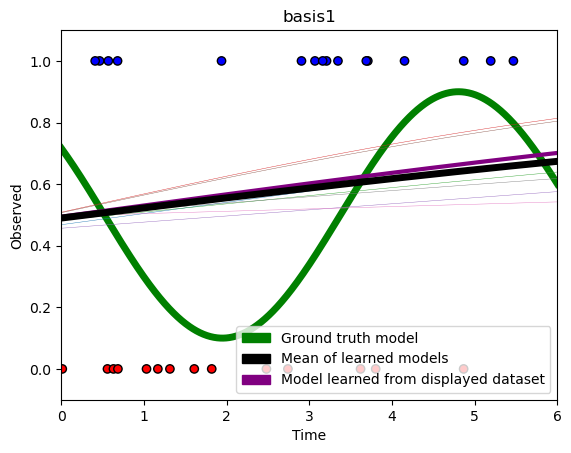

[basis1] avg squared bias = 0.06721   avg variance = 0.00303


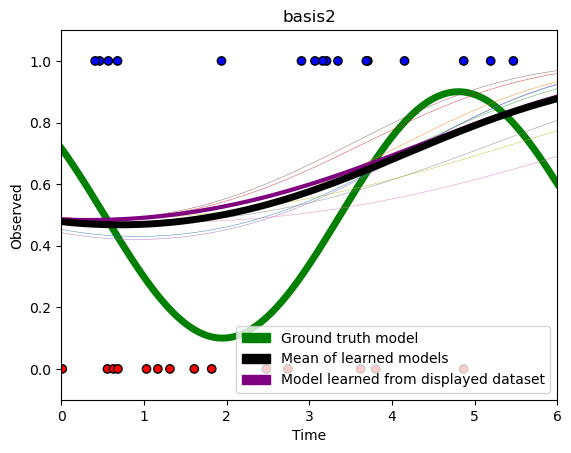

[basis2] avg squared bias = 0.04858   avg variance = 0.00340
Classification probabilities for t = 0.1: 0.46831792964985014, t = 3.2: 0.00043877049886759464
Model variances for t = 0.1: 0.0004975253968752364, t = 3.2: 0.20975748264879943


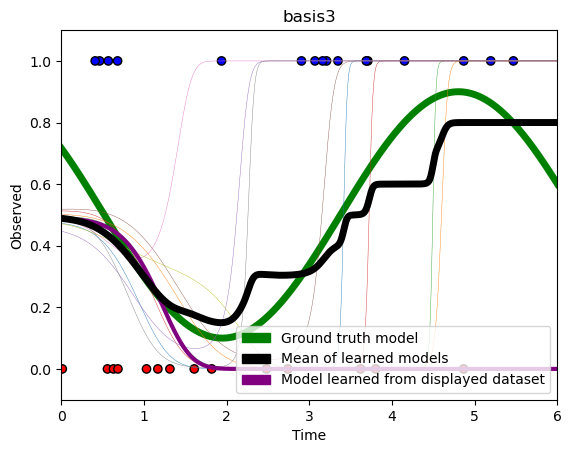

[basis3] avg squared bias = 0.01174   avg variance = 0.13659


In [7]:
def plot_results(basis, title):
    eta = 0.001
    runs = 1000

    # For Problem 1.4
    test_points_1 = []
    test_points_2 = []
    t1 = basis(np.array([0.1]))
    t2 = basis(np.array([3.2]))

    all_models = []
    for i in range(10):
        x, y = t_obs[i], y_obs[i]
        x_transformed = basis(x)
        model = LogisticRegressor(eta=eta, runs=runs)
        model.fit(x_transformed, y, np.zeros((x_transformed.shape[1], 1)))
        all_models.append(model)

        if basis == basis3:
            # extract values from (1 x 1) array
            pred_1 = model.predict(t1)[0, 0]
            pred_2 = model.predict(t2)[0, 0]
            if i == 0:
                print(f"Classification probabilities for t = 0.1: {pred_1}, t = 3.2: {pred_2}")
            test_points_1.append(pred_1)
            test_points_2.append(pred_2)

    if basis == basis3:
        print(f"Model variances for t = 0.1: {np.var(test_points_1)}, t = 3.2: {np.var(test_points_2)}")
    Y_hats = visualize_prediction_lines(x, y, all_models, basis, title)

    # --- bias / variance against the true generating process (for 1.3)
    grid = np.linspace(0, 6, 1000)
    truth = np.cos(1.1 * grid + 1) * 0.4 + 0.5
    mean_pred = Y_hats.mean(axis=0).reshape(-1)
    bias_sq = float(np.mean((truth - mean_pred) ** 2))
    var = float(np.mean(Y_hats.reshape(len(all_models), -1).var(axis=0)))
    print(f"[{title}] avg squared bias = {bias_sq:.5f}   avg variance = {var:.5f}")

plot_results(basis1, 'basis1')
plot_results(basis2, 'basis2')
plot_results(basis3, 'basis3')

## Problem 1, Subpart 6 — comparing the two telescopes

Quantifying how the alternate telescope's labels relate to ours (used in the write-up).

observation times identical: True
detection rate   ours 51.7%   alternate 67.7%
label agreement  49.3%
corr with f(t)   ours 0.5523   alternate 0.0378
P(alt=1 | ours=1) = 0.665
P(alt=1 | ours=0) = 0.690   <- essentially equal => uninformative

bin                 ours     alt   true f
[0.00,0.75)        0.55    0.65     0.56
[0.75,1.50)        0.28    0.75     0.25
[1.50,2.25)        0.07    0.68     0.10
[2.25,3.00)        0.22    0.62     0.21
[3.00,3.75)        0.60    0.62     0.50
[3.75,4.50)        0.79    0.71     0.79
[4.50,5.25)        0.93    0.72     0.90
[5.25,6.00)        0.79    0.71     0.75


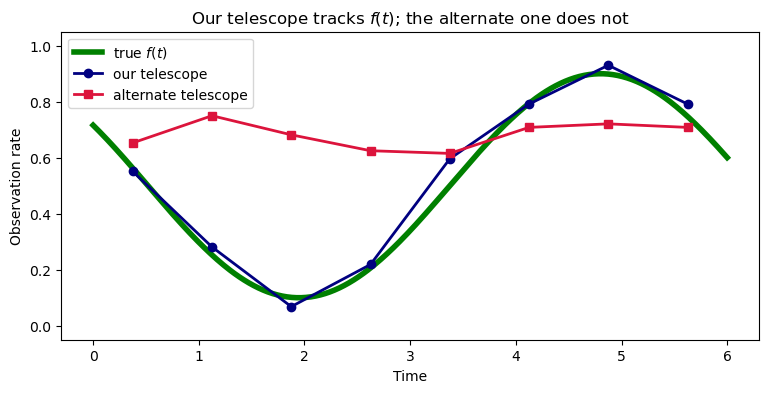

In [8]:
alt = np.genfromtxt("data/planet-obs-alternate.csv", delimiter=',', skip_header=1)
t_alt, y_alt = alt[:, 1], alt[:, 2]

raw = np.genfromtxt("data/planet-obs.csv", delimiter=',')
t_ours, y_ours = raw[:, 0], raw[:, 1]

o, oa = np.argsort(t_ours), np.argsort(t_alt)
t_s, y_s, ya_s = t_ours[o], y_ours[o], y_alt[oa]
f = lambda s: np.cos(1.1 * s + 1) * 0.4 + 0.5

print(f"observation times identical: {np.allclose(t_s, t_alt[oa])}")
print(f"detection rate   ours {y_s.mean():.1%}   alternate {ya_s.mean():.1%}")
print(f"label agreement  {np.mean(y_s == ya_s):.1%}")
print(f"corr with f(t)   ours {np.corrcoef(y_s, f(t_s))[0,1]:.4f}   alternate {np.corrcoef(ya_s, f(t_s))[0,1]:.4f}")
print(f"P(alt=1 | ours=1) = {ya_s[y_s==1].mean():.3f}")
print(f"P(alt=1 | ours=0) = {ya_s[y_s==0].mean():.3f}   <- essentially equal => uninformative")

edges = np.linspace(0, 6, 9)
print(f"\n{'bin':<16}{'ours':>8}{'alt':>8}{'true f':>9}")
for a, b in zip(edges[:-1], edges[1:]):
    m = (t_s >= a) & (t_s < b)
    print(f"[{a:.2f},{b:.2f}){'':<4}{y_s[m].mean():>8.2f}{ya_s[m].mean():>8.2f}{f((a+b)/2):>9.2f}")

ctr = (edges[:-1] + edges[1:]) / 2
plt.figure(figsize=(9, 4))
g = np.linspace(0, 6, 400)
plt.plot(g, f(g), 'g', lw=4, label='true $f(t)$')
plt.plot(ctr, [y_s[(t_s>=a)&(t_s<b)].mean() for a,b in zip(edges[:-1],edges[1:])],
         'o-', color='navy', lw=2, label='our telescope')
plt.plot(ctr, [ya_s[(t_s>=a)&(t_s<b)].mean() for a,b in zip(edges[:-1],edges[1:])],
         's-', color='crimson', lw=2, label='alternate telescope')
plt.xlabel('Time'); plt.ylabel('Observation rate'); plt.ylim(-0.05, 1.05); plt.legend()
plt.title('Our telescope tracks $f(t)$; the alternate one does not')
plt.savefig('img_output/p1.6_telescopes.png', bbox_inches='tight', dpi=140)
plt.show()

# Problem 3

In [9]:
class GaussianGenerativeModel:
    def __init__(self, is_shared_covariance=False):
        self.is_shared_covariance = is_shared_covariance

    def fit(self, X, y):
        """
        Compute the means and (shared) covariance matrix of the data. Compute the prior over y.
        These are the maximum-likelihood estimators derived in Problem 2.

        :param X: a 2D numpy array of (transformed) feature values. Shape is (n x 2)
        :param y: a 1D numpy array of target values (Automatically Rejected=0, Require Guarantor=1, Automatically Accepted=2).
        :return: None
        """
        self.K = int(y.max()) + 1
        n, d = X.shape
        self.pi  = np.array([(y == k).mean() for k in range(self.K)])           # pi_k = n_k / n
        self.mus = np.array([X[y == k].mean(axis=0) for k in range(self.K)])    # mu_k = class mean

        if self.is_shared_covariance:
            # Sigma = (1/n) * within-class scatter POOLED over classes
            S = np.zeros((d, d))
            for k in range(self.K):
                Z = X[y == k] - self.mus[k]
                S += Z.T @ Z
            self.Sigma = S / n
            self.Sigmas = [self.Sigma] * self.K
        else:
            # Sigma_k = (1/n_k) * within-class scatter for class k alone
            self.Sigmas = []
            for k in range(self.K):
                Z = X[y == k] - self.mus[k]
                self.Sigmas.append(Z.T @ Z / len(Z))

    def _joint_log(self, X):
        """log p(x | C_k) + log pi_k for every class. Shape (n, K)."""
        X = np.atleast_2d(X)
        return np.stack([np.atleast_1d(mvn.logpdf(X, self.mus[k], self.Sigmas[k])) + np.log(self.pi[k])
                         for k in range(self.K)], axis=1)

    def predict(self, X_pred):
        """
        Predict classes of points given feature values in X_pred

        :param X_pred: a 2D numpy array of (transformed) feature values. Shape is (n x 2)
        :return: a 1D numpy array of predicted classes. Shape should be (n,)
        """
        return self._joint_log(np.atleast_2d(X_pred)).argmax(axis=1)

    def predict_proba(self, X_pred):
        L = self._joint_log(np.atleast_2d(X_pred))
        return np.exp(L - logsumexp(L, axis=1, keepdims=True))

    def negative_log_likelihood(self, X, y):
        """
        Given the data X, use previously calculated class means and covariance matrix to
        calculate the negative log likelihood of the data
        """
        L = self._joint_log(X)
        return float(-L[np.arange(len(y)), y].sum())

In [10]:
class SoftmaxRegression:
    def __init__(self, eta, lam, verbose=True):
        self.eta = eta
        self.lam = lam
        self.W = None
        self.verbose = verbose

    # Some helper functions may go here:
    @staticmethod
    def _augment(X):
        """Prepend the bias column."""
        X = np.atleast_2d(np.asarray(X, dtype=float))
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y, runs=200000):
        """
        Fit the weights W of softmax regression using gradient descent with L2 regularization.
        The gradient is the Problem 2 result: Phi^T (softmax(Phi W) - Y), plus lam * W
        for every weight EXCEPT the bias.

        :param X: a 2D numpy array of (transformed) feature values. Shape is (n x 2)
        :param y: a 1D numpy array of target values.
        :return: None
        """
        Xb = self._augment(X)
        n, D = Xb.shape
        K = int(y.max()) + 1
        Y = np.zeros((n, K)); Y[np.arange(n), y] = 1

        W = np.ones((D, K))                            # initialise to ONES; bias is row 0
        for _ in range(runs):
            G = Xb.T @ (softmax(Xb @ W, axis=1) - Y)   # summed over data points (not averaged)
            R = self.lam * W.copy()
            R[0, :] = 0                                # do NOT regularize the bias
            W -= self.eta * (G + R)
            if self.verbose and (_ + 1) % 50000 == 0:
                print(f"  iter {_ + 1:>6d}/{runs}")
        self.W = W.T                                   # stored as (K, D)

    # Input is (n x 2) array
    def predict(self, X_pred):
        """
        :return: a 1D numpy array of predicted classes. Shape should be (n,)
        """
        return self.predict_proba(X_pred).argmax(axis=1)

    # Input is (n x 2) array
    def predict_proba(self, X_pred):
        """
        :return: a 2D numpy array of predicted class probabilities. Shape should be (n x 3)
        """
        return softmax(self._augment(X_pred) @ self.W.T, axis=1)

In [11]:
class KNNClassifier:
    def __init__(self, k):
        self.X = None
        self.y = None
        self.K = k

    # Helper functions go here:
    @staticmethod
    def distance(a, b):
        """dist(x, x') = (x1 - x1')^2 / 9 + (x2 - x2')^2"""
        return (a[0] - b[0]) ** 2 / 9 + (a[1] - b[1]) ** 2

    def fit(self, X, y):
        """
        In KNN, "fitting" can be as simple as storing the data, so this has been written for you.
        """
        self.X = X
        self.y = y

    def predict(self, X_pred_many):
        """
        Predict classes of points given feature values in X_pred

        :param X_pred: a 2D numpy array of (transformed) feature values. Shape is (n x 2)
        :return: a 1D numpy array of predicted classes. Shape should be (n,)
        """
        P = np.atleast_2d(np.asarray(X_pred_many, dtype=float))
        # vectorised version of self.distance over every (query, train) pair
        D = (P[:, 0:1] - self.X[:, 0]) ** 2 / 9 + (P[:, 1:2] - self.X[:, 1]) ** 2
        idx = np.argsort(D, axis=1, kind='stable')[:, :self.K]
        votes = self.y[idx]
        # plurality vote; ties break toward the smaller class index
        return np.array([np.bincount(v, minlength=int(self.y.max()) + 1).argmax()
                         for v in votes])

In [12]:
def phi(X):
    """
    Transform [x_1, x_2] into basis [ln(x_1 + 10), x_2^2]

    :param t: a 2D numpy array of values to transform. Shape is (n x 2)
    :return: a 2D array in which each row corresponds to a basis transformation of
             an input value. Shape should be (n x 2)
    """
    X = np.asarray(X, dtype=float)
    return np.stack([np.log(X[:, 0] + 10), X[:, 1] ** 2], axis=1)

## Plotting Function for Problem 3, Subpart 1

In [13]:
# Visualize the decision boundary that a model produces
def visualize_boundary(model, X, y, title, basis=None, width=10):
    # Create a grid of points
    x_min, x_max = min(X[:, 0]-width*0.15), max(X[:, 0]+width*0.15)
    y_min, y_max = min(X[:, 1]-width*0.2), max(X[:, 1]+width*0.2)
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.05),
        np.arange(y_min, y_max, 0.05)
    )

    # Flatten the grid so the values match spec for self.predict
    xx_flat = xx.flatten()
    yy_flat = yy.flatten()
    X_pred = np.vstack((xx_flat, yy_flat)).T

    if basis is not None:
        X_pred = basis(X_pred)

    # Get the class predictions
    Y_hat = model.predict(X_pred)
    Y_hat = Y_hat.reshape((xx.shape[0], xx.shape[1]))

    # Visualize them.
    cmap = c.ListedColormap(['r', 'b', 'g'])
    plt.figure()
    plt.title(title)
    plt.xlabel('Debt to Income Ratio')
    plt.ylabel('Credit Score')

    ticks = np.transpose(np.array([[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7],
                                   [300, 400, 500, 600, 700, 800, 900, 1000]]))
    transformed_ticks = transform(ticks)

    plt.xticks(transformed_ticks[:,0], ticks[:,0])
    plt.yticks(transformed_ticks[:,1], ticks[:,1])
    plt.pcolormesh(xx, yy, Y_hat, cmap=cmap, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, linewidths=1,
                edgecolors='black')

    # Adding a legend and a title
    red = mpatches.Patch(color='red', label='Automatically Rejected')
    blue = mpatches.Patch(color='blue', label='Require Guarantor')
    green = mpatches.Patch(color='green', label='Automatically Accepted')
    plt.legend(handles=[red, blue, green])

    # Saving the image to a file, and showing it as well
    plt.savefig('img_output/' + title + '.png', bbox_inches='tight', dpi=140)
    plt.show()

## Problem 3, Subpart 1

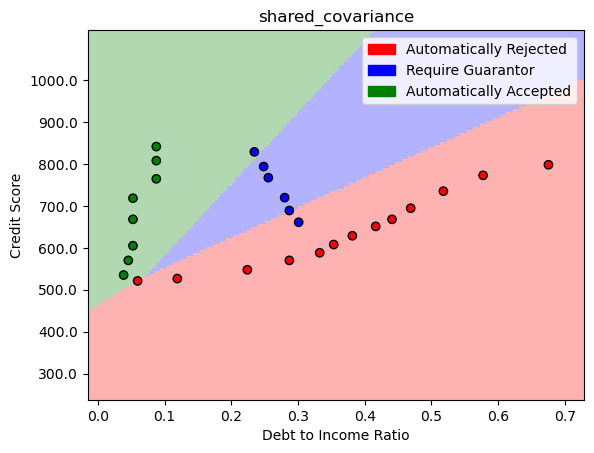

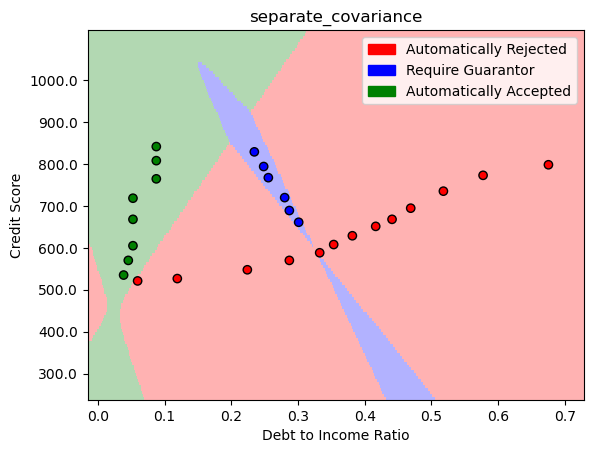

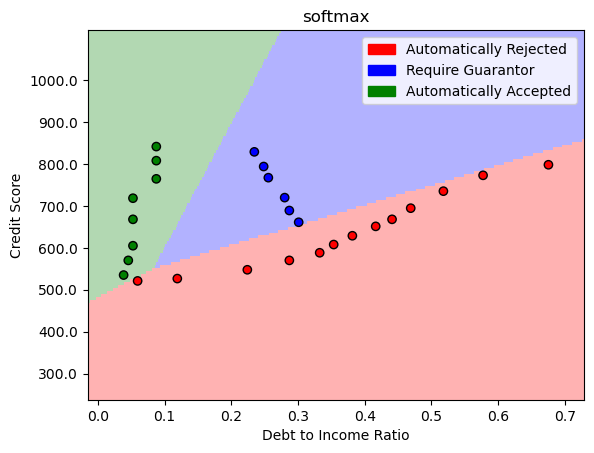

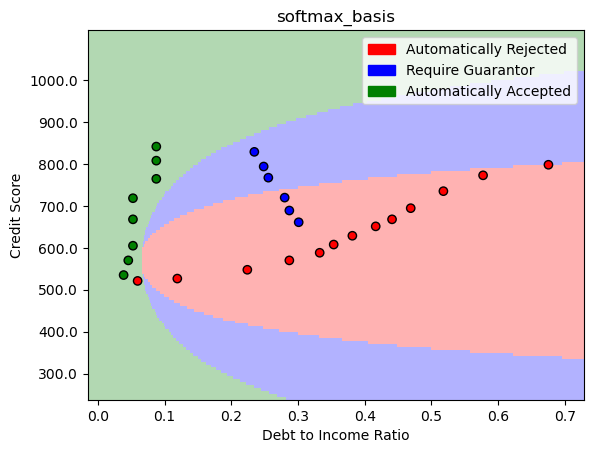

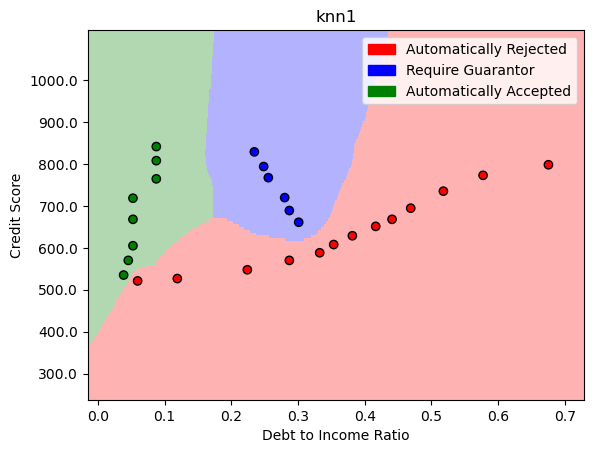

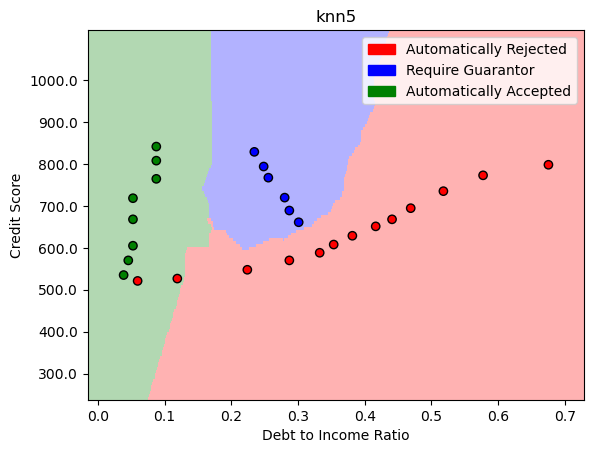

training accuracy:
  shared       0.926
  separate     1.000
  softmax      1.000
  softmax+phi  0.852
  knn1         1.000
  knn5         0.926


In [14]:
# Fit models and visualize their decision boundaries
shared = GaussianGenerativeModel(is_shared_covariance=True)
shared.fit(X_applicants, y_applicants)

separate = GaussianGenerativeModel(is_shared_covariance=False)
separate.fit(X_applicants, y_applicants)

softmax_model = SoftmaxRegression(eta=0.001, lam=0.001, verbose=False)
softmax_model.fit(X_applicants, y_applicants)

softmax_basis = SoftmaxRegression(eta=0.001, lam=0.001, verbose=False)
softmax_basis.fit(phi(X_applicants), y_applicants)

knn1 = KNNClassifier(1); knn1.fit(X_applicants, y_applicants)
knn5 = KNNClassifier(5); knn5.fit(X_applicants, y_applicants)

visualize_boundary(shared,        X_applicants, y_applicants, 'shared_covariance')
visualize_boundary(separate,      X_applicants, y_applicants, 'separate_covariance')
visualize_boundary(softmax_model, X_applicants, y_applicants, 'softmax')
visualize_boundary(softmax_basis, X_applicants, y_applicants, 'softmax_basis', basis=phi)
visualize_boundary(knn1,          X_applicants, y_applicants, 'knn1')
visualize_boundary(knn5,          X_applicants, y_applicants, 'knn5')

print("training accuracy:")
for nm, m, b in [("shared", shared, None), ("separate", separate, None),
                 ("softmax", softmax_model, None), ("softmax+phi", softmax_basis, phi),
                 ("knn1", knn1, None), ("knn5", knn5, None)]:
    P = b(X_applicants) if b is not None else X_applicants
    print(f"  {nm:<12} {np.mean(m.predict(P) == y_applicants):.3f}")

In [15]:
# You may test your models' correctness using test_p3_softmax and test_p3_knn
test_p3_softmax(softmax_model, softmax_basis)
test_p3_knn(knn1, knn5)

Passed softmax regression tests
Passed KNN tests


## Problem 3, Subpart 2

In [16]:
# Predicting for new applicant
point = transform(np.array([(0.32, 350)]))
print("transformed point:", point)

names = ["Automatically Rejected", "Require Guarantor", "Automatically Accepted"]
for label, model, basis in [("(a) shared cov",    shared,        None),
                            ("(b) separate cov",  separate,      None),
                            ("(c) softmax",       softmax_model, None),
                            ("(d) softmax + phi", softmax_basis, phi),
                            ("(e) kNN k=1",       knn1,          None),
                            ("(e) kNN k=5",       knn5,          None)]:
    P = basis(point) if basis is not None else point
    k = int(model.predict(P)[0])
    probs = ""
    if hasattr(model, 'predict_proba'):
        probs = "   probs = " + np.array2string(model.predict_proba(P)[0], precision=6)
    print(f"{label:<20} -> {k} ({names[k]}){probs}")

transformed point: [[ 1.64285714 -1.57142857]]
(a) shared cov       -> 0 (Automatically Rejected)   probs = [9.999991e-01 8.544919e-07 4.217463e-10]
(b) separate cov     -> 0 (Automatically Rejected)   probs = [1. 0. 0.]
(c) softmax          -> 0 (Automatically Rejected)   probs = [1.000000e+00 5.731858e-23 1.548767e-33]
(d) softmax + phi    -> 1 (Require Guarantor)   probs = [2.196922e-01 7.802357e-01 7.210762e-05]
(e) kNN k=1          -> 0 (Automatically Rejected)
(e) kNN k=5          -> 0 (Automatically Rejected)


## Problem 4

In [17]:
# -----------------------------
# Synthetic 2D regression problem
# -----------------------------

def make_problem(n: int = 120, seed: int = 0) -> Tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)

    # correlated + differently-scaled features -> ravine in loss
    x0 = rng.normal(size=n)
    x1 = 0.12 * x0
    X = np.stack([x0, x1], axis=1)
    w_true = np.array([300.0, -200])
    y = X @ w_true + 0.12 * rng.normal(size=n)

    # standardize
    X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-12)
    y = y - y.mean()
    return X, y

In [18]:
# -----------------------------
# Losses + gradients
# -----------------------------
def loss_linear(X, y, w):
    """Linear regression loss: L(w) = (1/2n) * sum_i (x_i^T w - y_i)^2"""
    r = X @ w - y
    return 0.5 * np.dot(r, r) / len(y)

def grad_linear(X, y, w):
    """Gradient of the linear regression loss w.r.t. w."""
    return X.T @ (X @ w - y) / len(y)

def mse(X, y, w):
    """Mean squared error (no 1/2 factor). Used for plotting."""
    r = X @ w - y
    return np.dot(r, r) / len(y)

def loss_ridge(X, y, w, lam):
    """Ridge loss: linear loss + (lambda/2) * ||w||^2"""
    return loss_linear(X, y, w) + 0.5 * lam * np.dot(w, w)

def grad_ridge(X, y, w, lam):
    """Gradient of ridge loss: grad_linear + lambda * w"""
    return grad_linear(X, y, w) + lam * w

In [19]:
# -----------------------------
# Optimizers (stateful)
# -----------------------------
@dataclass
class MomState:
    v: np.ndarray

def sgd_step(w, g, lr, state=None):
    """SGD update: w_{t+1} = w_t - lr * g_t"""
    return w - lr * g, None

def mom_step(w, g, lr, beta, state: MomState | None):
    """
    Momentum update:
        v_{t+1} = beta * v_t + g_t
        w_{t+1} = w_t - lr * v_{t+1}
    """
    if state is None:
        state = MomState(v=np.zeros_like(w))
    state.v = beta * state.v + g
    return w - lr * state.v, state

@dataclass
class AdamState:
    m: np.ndarray
    v: np.ndarray
    t: int

def adam_step(w, g, lr, beta1, beta2, eps, state: AdamState | None):
    """
    Adam update with bias correction.
    """
    if state is None:
        state = AdamState(m=np.zeros_like(w), v=np.zeros_like(w), t=0)
    state.t += 1
    state.m = beta1 * state.m + (1 - beta1) * g
    state.v = beta2 * state.v + (1 - beta2) * (g * g)
    m_hat = state.m / (1 - beta1 ** state.t)
    v_hat = state.v / (1 - beta2 ** state.t)
    return w - lr * m_hat / (np.sqrt(v_hat) + eps), state

## Graphing Code

In [20]:
def contour_panel(
    ax,
    title,
    loss_fn: Callable[[np.ndarray], float],
    path: np.ndarray,
    both_opt: tuple = None
):
    # ----------------------------------
    # Build contour grid
    # ----------------------------------
    pad_frac = 0.3
    w0_lo, w0_hi = 40, 300
    w1_lo, w1_hi = -75, 175

    w0_pad = pad_frac * max(w0_hi - w0_lo, 1.0)
    w1_pad = pad_frac * max(w1_hi - w1_lo, 1.0)

    w0s = np.linspace(w0_lo - w0_pad, w0_hi + w0_pad, 300)
    w1s = np.linspace(w1_lo - w1_pad, w1_hi + w1_pad, 300)

    W0, W1 = np.meshgrid(w0s, w1s)

    Z = np.zeros_like(W0)
    for i in range(Z.shape[0]):
        pts = np.stack([W0[i], W1[i]], axis=1)
        Z[i] = np.array([loss_fn(p) for p in pts])

    # ----------------------------------
    # Plot contours
    # ----------------------------------
    ax.contourf(W0, W1, Z, levels=40, cmap=cm.turbo)
    ax.contour(W0, W1, Z, levels=18, linewidths=0.7, cmap=cm.turbo)

    # ----------------------------------
    # Plot path
    # ----------------------------------
    ax.plot(path[:, 0], path[:, 1], c="white", linewidth=0.8, alpha=0.5)

    n_pts = len(path)
    norm = Normalize(vmin=0, vmax=n_pts - 1)
    cmap = cm.magma

    ax.scatter(path[:, 0], path[:, 1], c=np.arange(n_pts), cmap=cmap, norm=norm,
               s=35, edgecolor="white", linewidths=0.4, zorder=5)

    # Start (square) and end (star)
    colors = cmap(norm(np.arange(n_pts)))
    ax.scatter([path[0, 0]], [path[0, 1]], marker="s", s=120, c=[colors[0]],
               edgecolor="white", linewidths=1.5, zorder=6)
    ax.scatter([path[-1, 0]], [path[-1, 1]], marker="*", s=220, c=[colors[-1]],
               edgecolor="white", linewidths=1.5, zorder=6)

    # ----------------------------------
    # Plot optima
    # ----------------------------------
    if both_opt is not None:
        opt_1, opt_2 = both_opt

        # Line of solutions. NOTE: the release notebook hard-codes w1 = 276 - w0,
        # but for this data the true line of OLS optima is w0 + w1 = 263.55,
        # so we draw the true one (and the hard-coded one dashed grey for reference).
        opt_line_x = np.linspace(70, 300, 500)
        if opt_1 is not None:
            s_star = opt_1.sum()
            ax.plot(opt_line_x, s_star - opt_line_x, 'r--', linewidth=2, label='opt_1')
        ax.plot(opt_line_x, 276 - opt_line_x, ':', color='grey', linewidth=1.2,
                label='opt_1 (as hard-coded)')

        if opt_2 is not None:
            ax.scatter(opt_2[0], opt_2[1], marker="x", s=160, c="blue",
                       linewidths=3, label="opt_2", zorder=7)

        ax.legend(fontsize=8)

    # ----------------------------------
    ax.set_title(title)
    ax.set_xlabel("w0")
    ax.set_ylabel("w1")

    ax.set_xlim(40, 300)
    ax.set_ylim(-75, 175)

In [21]:
# -----------------------------
# Run + record path
# -----------------------------
def run(
    grad_fn: Callable[[np.ndarray], np.ndarray],
    w0: np.ndarray,
    steps: int,
    stepper: Callable,
    stepper_kwargs: dict,
):
    w = w0.copy()
    path = [w.copy()]
    state = None
    for _ in range(steps):
        g = grad_fn(w)
        w, state = stepper(w, g, **stepper_kwargs, state=state)
        path.append(w.copy())
    return np.array(path)

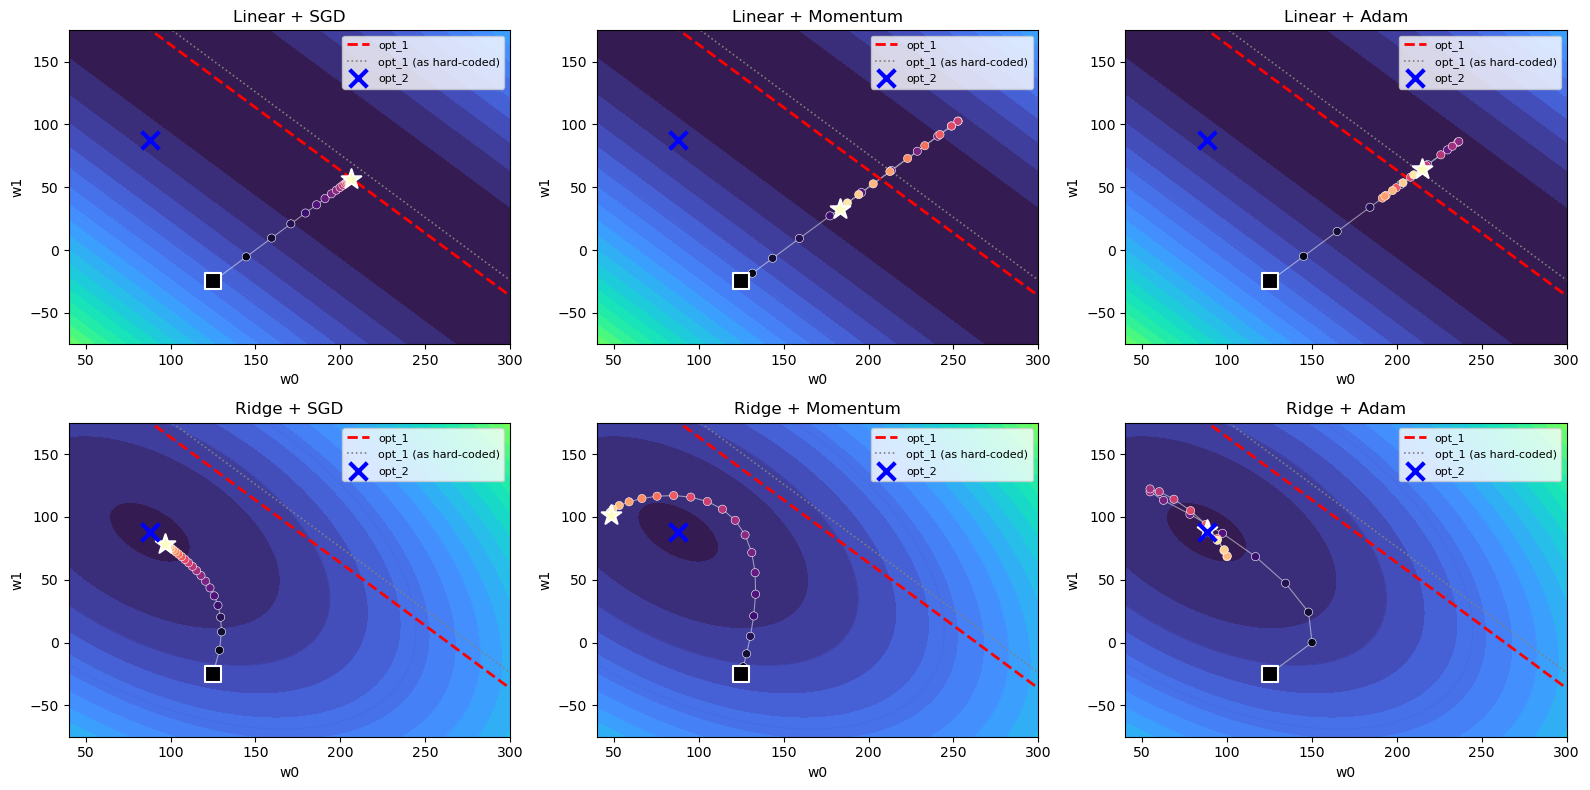

In [22]:
X, y = make_problem(seed=0)
w_start = np.array([125.0, -25.0])

steps = 20
lam = 1

# OLS optimum (depends on w_true through the generated data)
w_opt_lin = np.linalg.lstsq(X, y, rcond=None)[0]
# Ridge closed-form optimum
I = np.eye(X.shape[1])
w_opt_rid = np.linalg.solve(X.T @ X / len(y) + lam * I, X.T @ y / len(y))

# Objective-specific functions (closures over X,y)
lin_loss = lambda w: loss_linear(X, y, w)
lin_grad = lambda w: grad_linear(X, y, w)

rid_loss = lambda w: loss_ridge(X, y, w, lam)
rid_grad = lambda w: grad_ridge(X, y, w, lam)

# Hyperparams tuned so the paths look distinct + stable
sgd_lr_lin, mom_lr_lin, adam_lr_lin = 0.12, 0.04, 20
sgd_lr_rid, mom_lr_rid, adam_lr_rid = 0.10, 0.03, 25

beta = 0.9
beta1, beta2, eps = 0.8, 0.8, 1e-8

# --- Linear paths ---
p_lin_sgd  = run(lin_grad, w_start, steps, sgd_step,  dict(lr=sgd_lr_lin))
p_lin_mom  = run(lin_grad, w_start, steps, mom_step,  dict(lr=mom_lr_lin, beta=beta))
p_lin_adam = run(lin_grad, w_start, steps, adam_step, dict(lr=adam_lr_lin, beta1=beta1, beta2=beta2, eps=eps))

# --- Ridge paths ---
p_rid_sgd  = run(rid_grad, w_start, steps, sgd_step,  dict(lr=sgd_lr_rid))
p_rid_mom  = run(rid_grad, w_start, steps, mom_step,  dict(lr=mom_lr_rid, beta=beta))
p_rid_adam = run(rid_grad, w_start, steps, adam_step, dict(lr=adam_lr_rid, beta1=beta1, beta2=beta2, eps=eps))

# --- Contour plots ---
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

both_opt = (w_opt_lin, w_opt_rid)

contour_panel(axes[0, 0], "Linear + SGD",      lin_loss, p_lin_sgd,  both_opt)
contour_panel(axes[0, 1], "Linear + Momentum", lin_loss, p_lin_mom,  both_opt)
contour_panel(axes[0, 2], "Linear + Adam",     lin_loss, p_lin_adam, both_opt)

contour_panel(axes[1, 0], "Ridge + SGD",       rid_loss, p_rid_sgd,  both_opt)
contour_panel(axes[1, 1], "Ridge + Momentum",  rid_loss, p_rid_mom,  both_opt)
contour_panel(axes[1, 2], "Ridge + Adam",      rid_loss, p_rid_adam, both_opt)

plt.tight_layout()
plt.savefig('img_output/p4.6_contours.png', bbox_inches='tight', dpi=120)
plt.show()

### Problem 4.6 — diagnostics quoted in the write-up

In [23]:
s = np.linalg.svd(X, compute_uv=False)
H = X.T @ X / len(y)
ev = np.linalg.eigvalsh(H)

print(f"columns of X identical?        {np.allclose(X[:, 0], X[:, 1])}   -> rank {np.linalg.matrix_rank(X)}")
print(f"singular values of X:          {np.round(s, 4)}")
print(f"eigenvalues of X^T X / n:      {np.round(ev, 6)}  -> condition number infinite")
print(f"eigenvalues of ridge Hessian:  {np.round(ev + lam, 6)}  -> condition number {(ev.max()+lam)/(ev.min()+lam):.4f}")
print(f"\nline of OLS optima:  w0 + w1 = {w_opt_lin.sum():.4f}   (notebook hard-codes 276)")
print(f"ridge optimum:       {np.round(w_opt_rid, 4)}  ->  w0 + w1 = {w_opt_rid.sum():.4f} "
      f"(shrunk {100*(1-w_opt_rid.sum()/w_opt_lin.sum()):.1f}%)")

s_star = w_opt_lin.sum()
print(f"\n{'run':<22}{'final w':>22}{'dist to opt':>14}{'final loss':>14}")
for nm, p in [("Linear + SGD", p_lin_sgd), ("Linear + Momentum", p_lin_mom), ("Linear + Adam", p_lin_adam),
              ("Ridge + SGD", p_rid_sgd), ("Ridge + Momentum", p_rid_mom), ("Ridge + Adam", p_rid_adam)]:
    wf = p[-1]
    if nm.startswith("Linear"):
        d, L = abs(wf.sum() - s_star) / np.sqrt(2), lin_loss(wf)
    else:
        d, L = np.linalg.norm(wf - w_opt_rid), rid_loss(wf)
    print(f"{nm:<22}[{wf[0]:8.2f}, {wf[1]:8.2f}]{d:>14.4f}{L:>14.3f}")
print(f"\noptimal losses: linear {lin_loss(w_opt_lin):.3f}   ridge {rid_loss(w_opt_rid):.3f}")
print("(for the linear runs, 'dist' is the PERPENDICULAR distance to the line of optima)")

columns of X identical?        True   -> rank 1
singular values of X:          [15.4919  0.    ]
eigenvalues of X^T X / n:      [0. 2.]  -> condition number infinite
eigenvalues of ridge Hessian:  [1. 3.]  -> condition number 3.0000

line of OLS optima:  w0 + w1 = 263.5512   (notebook hard-codes 276)
ridge optimum:       [87.8504 87.8504]  ->  w0 + w1 = 175.7008 (shrunk 33.3%)

run                                  final w   dist to opt    final loss
Linear + SGD          [  206.44,    56.44]        0.4780         0.236
Linear + Momentum     [  183.06,    33.06]       33.5430      1125.142
Linear + Adam         [  214.62,    64.62]       11.0990       123.196
Ridge + SGD           [   96.94,    78.70]       12.8952     11659.695
Ridge + Momentum      [   48.20,   101.67]       41.9940     12791.919
Ridge + Adam          [   88.06,    89.46]        1.6178     11579.496

optimal losses: linear 0.008   ridge 11576.550
(for the linear runs, 'dist' is the PERPENDICULAR distance to the line o